## Project 3: Knowledge Graph Structure Analyzer

**Goal:** Build a directed, attributed knowledge graph and analyze its structure.

**Important limitation:** NetworkX performs *structural* analysis only. It does not perform semantic inference, ontology reasoning, or logic-based queries. We can count paths but not infer new facts from relationships.

In [1]:
# ═══════════════════════════════════════════════════════════════════════
# PROJECT 3 — Knowledge Graph
# Entities: people, organizations, concepts
# Typed relationships: works_at, founded, studies, part_of, etc.
# ═══════════════════════════════════════════════════════════════════════


import networkx as nx
import matplotlib.pyplot as plt
KG = nx.DiGraph()

# Entities with types
KG.add_nodes_from([
    ("Alice",        {"type": "Person"}),
    ("Bob",          {"type": "Person"}),
    ("DeepMind",     {"type": "Organization"}),
    ("Google",       {"type": "Organization"}),
    ("MachineLearning", {"type": "Concept"}),
    ("NeuralNetworks",  {"type": "Concept"}),
    ("Python",          {"type": "Technology"}),
    ("TensorFlow",      {"type": "Technology"}),
    ("AlphaGo",         {"type": "Project"}),
])

# Typed relationships
KG.add_edges_from([
    ("Alice",         "DeepMind",       {"relation": "works_at"}),
    ("Alice",         "MachineLearning",{"relation": "studies"}),
    ("Alice",         "Python",         {"relation": "uses"}),
    ("Bob",           "Google",         {"relation": "works_at"}),
    ("Bob",           "TensorFlow",     {"relation": "developed"}),
    ("Bob",           "MachineLearning",{"relation": "studies"}),
    ("DeepMind",      "Google",         {"relation": "acquired_by"}),
    ("DeepMind",      "AlphaGo",        {"relation": "created"}),
    ("AlphaGo",       "MachineLearning",{"relation": "uses"}),
    ("AlphaGo",       "NeuralNetworks", {"relation": "uses"}),
    ("MachineLearning","NeuralNetworks",{"relation": "includes"}),
    ("TensorFlow",    "Python",         {"relation": "supports"}),
    ("TensorFlow",    "NeuralNetworks", {"relation": "implements"}),
])




## Basic Structure


In [2]:
print("=" * 60)
print("Project: Build a fake knowledge graph")
print("=" * 60)

print(f"\n Entities (nodes): {KG.number_of_nodes()}")
print(f"Relationships (edges): {KG.number_of_edges()}")

# In-degree and out-degree

print(f" {'Entity':20s} {'Type':14s}  {'In-Degree':5s}  {'Out-Degree':5s}")
print(" " + "-" * 60)

for nodes in sorted(KG.nodes()):
    entity_type = KG.nodes[nodes].get("type", "Unknown")
    print(f" {nodes:20s} {entity_type:14s} {KG.in_degree(nodes):5d} {KG.out_degree(nodes):5d}")

Project: Build a fake knowledge graph

 Entities (nodes): 9
Relationships (edges): 13
 Entity               Type            In-Degree  Out-Degree
 ------------------------------------------------------------
 Alice                Person             0     3
 AlphaGo              Project            1     2
 Bob                  Person             0     3
 DeepMind             Organization       1     2
 Google               Organization       2     0
 MachineLearning      Concept            3     1
 NeuralNetworks       Concept            3     0
 Python               Technology         2     0
 TensorFlow           Technology         1     2


In [3]:
## Weakly connected components
wccs = list(nx.weakly_connected_components(KG))
print(f"Weakly connected components: {len(wccs)}")

for i, wcc in enumerate(wccs):
    print(f"  WCC-{i+1}: {sorted(wcc)}")

Weakly connected components: 1
  WCC-1: ['Alice', 'AlphaGo', 'Bob', 'DeepMind', 'Google', 'MachineLearning', 'NeuralNetworks', 'Python', 'TensorFlow']


## Betweeness: Most important intermediate node

In [4]:
bet = nx.betweenness_centrality(KG)
print("\n Most important intermediary entities (betweeness):")

for node, score in sorted(bet.items(), key=lambda x: x[1], reverse=True):
    etype = KG.nodes[node].get("type", "Unknown")
    print(f" {node:20s} {etype:14s} {score:.3f}")


 Most important intermediary entities (betweeness):
 DeepMind             Organization   0.036
 AlphaGo              Project        0.036
 MachineLearning      Concept        0.027
 TensorFlow           Technology     0.027
 Alice                Person         0.000
 Bob                  Person         0.000
 Google               Organization   0.000
 NeuralNetworks       Concept        0.000
 Python               Technology     0.000


## Reachability: Can Alice reach (learn!!!) Neural Networks?

In [6]:
## Reachability: Can Alice reach Neural Networks?
print("\n Reachability: Can Alice reach Neural Networks?")
print(f" {nx.has_path(KG, 'Alice', 'NeuralNetworks')} ")
path = nx.shortest_path(KG, 'Alice', 'NeuralNetworks')
print(f" Shortest path: {path}")

print(f"  Explaination Path: {' → '.join(path)}")


 Reachability: Can Alice reach Neural Networks?
 True 
 Shortest path: ['Alice', 'MachineLearning', 'NeuralNetworks']
  Explaination Path: Alice → MachineLearning → NeuralNetworks


## Visualization,

{('Alice',
  'DeepMind'): Text(0.06648854917330316, -0.11907709396602462, 'works_at'),
 ('Alice',
  'MachineLearning'): Text(0.16373793164256423, 0.014308361437654016, 'studies'),
 ('Alice', 'Python'): Text(0.4946557509017955, -0.40856396892073665, 'uses'),
 ('Bob',
  'Google'): Text(-0.2637668598227718, -0.10810137514298401, 'works_at'),
 ('Bob',
  'TensorFlow'): Text(0.03200096292644217, -0.053204045445697457, 'developed'),
 ('Bob',
  'MachineLearning'): Text(-0.10337525751894816, 0.14630473666914123, 'studies'),
 ('DeepMind',
  'Google'): Text(-0.4509395072284271, -0.063558312767374, 'acquired_by'),
 ('DeepMind',
  'AlphaGo'): Text(-0.3166355466104599, 0.1759761804004889, 'created'),
 ('MachineLearning',
  'NeuralNetworks'): Text(-0.14803533162637794, 0.5176743662161407, 'includes'),
 ('TensorFlow',
  'Python'): Text(0.5567675049984575, -0.3717893526593459, 'supports'),
 ('TensorFlow',
  'NeuralNetworks'): Text(0.1558067122145459, 0.07982790477297419, 'implements'),
 ('AlphaGo',
  '

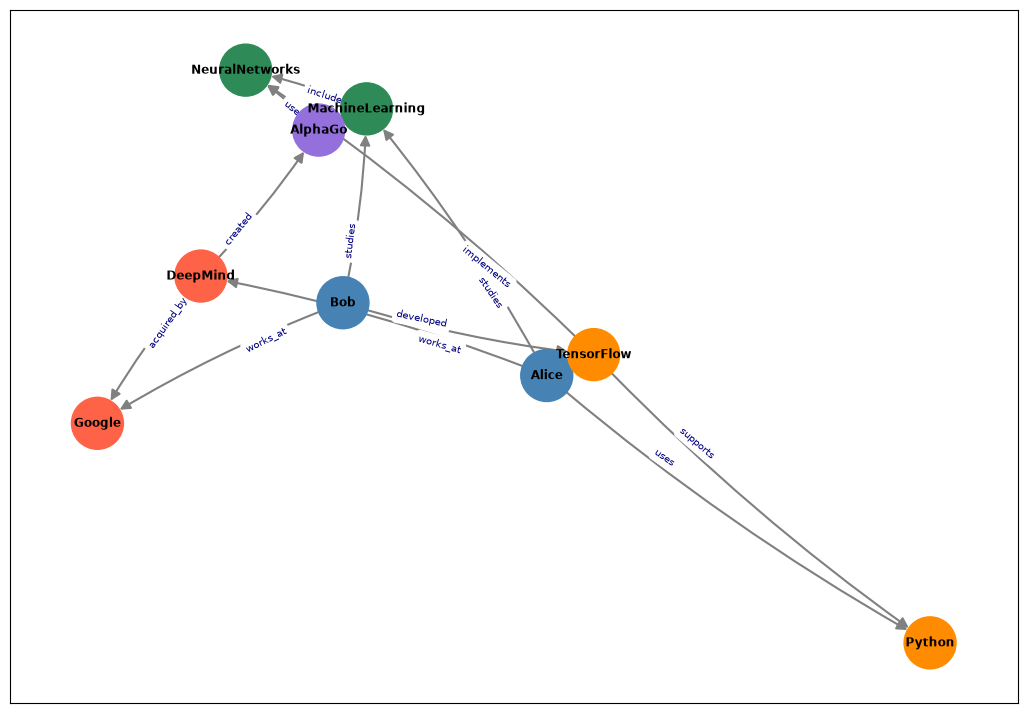

In [7]:
plt.figure(figsize=(13, 9))
pos = nx.spring_layout(KG, seed=42)

type_colors = {
    "Person": "steelblue", 
    "Organization": "tomato",
    "Concept": "seagreen", 
    "Technology": "darkorange", 
    "Project": "mediumpurple"
}

nc = [
    type_colors.get(KG.nodes[n].get("type", "Unknown"), "gray") for  n in KG.nodes()
]

edge_labels = {
    (u, v): d["relation"] for u, v, d in KG.edges(data=True)
}


nx.draw_networkx(KG, pos,
node_color=nc,
    node_size=1400,
    font_size=8.5,
    font_weight="bold",
    edge_color="gray",
    arrows=True,
    arrowsize=15,
    width=1.5,
    connectionstyle="arc3,rad=0.05",

)

nx.draw_networkx_edge_labels(KG, pos, edge_labels=edge_labels, font_size=7.5,
                              font_color="navy", label_pos=0.3)

In [8]:
print("\n--- LIMITATIONS NOTE ---")
print("NetworkX does NOT understand semantic meaning of relationships.")
print("'works_at' and 'acquired_by' are just edge labels — NetworkX treats")
print("them identically for path/centrality algorithms.")
print("For semantic reasoning (e.g., inferring Alice works at Google because")
print("DeepMind was acquired by Google), use an ontology reasoner like OWL/SPARQL.")


--- LIMITATIONS NOTE ---
NetworkX does NOT understand semantic meaning of relationships.
'works_at' and 'acquired_by' are just edge labels — NetworkX treats
them identically for path/centrality algorithms.
For semantic reasoning (e.g., inferring Alice works at Google because
DeepMind was acquired by Google), use an ontology reasoner like OWL/SPARQL.
